## Examining semicondictor yield

What affects semiconductor yield?

Data source: https://www.kaggle.com/datasets/luthfimuthathohirin/global-ai-semiconductor-supply-chain-telemetry?select=global_ai_semiconductor_supply_chain_enriched_2026.csv

### Initial setup and data loading

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme()
%matplotlib inline
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
semi = pd.read_csv('data/global_ai_semiconductor_supply_chain_enriched_2026.csv')

### Exploratory analysis

In [3]:
semi.head()

,facility_id,company_name,country_location,facility_type,process_node_nm,wafer_size_mm,monthly_capacity_wafers,capacity_utilization_pct,die_yield_pct,defect_density_per_cm2,...,geopolitical_risk_index,target_ai_accelerator_family,supply_chain_vulnerability_score,advanced_node_tier,foundry_market_power_index,chiplet_disaggregation_readiness,hbm_bandwidth_tb_s,ai_wafer_allocation_priority,cot_semiconductor_risk_rationale,confidence_score
0,FAB-SMIC-00CCF968,SMIC,China,Foundry,7nm,300,90373,82.0,94.3,0.079,...,8.4,AWS Trainium 2,62.38,Advanced_FinFET_4nm_7nm,4.6,Hybrid_Modular,1.20,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-00CCF968' yang dioperasika...,0.975
1,FAB-SMIC-02D12E75,SMIC,China,Foundry,7nm,300,61469,86.3,93.9,0.092,...,9.5,Custom Hyperscaler ASIC,58.73,Advanced_FinFET_4nm_7nm,4.6,Monolithic_Die,0.82,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-02D12E75' yang dioperasika...,0.979
2,FAB-SMIC-03578D8E,SMIC,China,Foundry,12nm,300,85323,79.2,94.6,0.039,...,7.2,Google TPU v5 / v6,50.68,Mature_Planar_Nodes,4.6,Monolithic_Die,0.00,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-03578D8E' yang dioperasika...,0.977
3,FAB-SMIC-03BC7BA8,SMIC,China,Foundry,7nm,300,58588,75.7,87.8,0.084,...,9.2,NVIDIA Hopper H100 / H200,59.10,Advanced_FinFET_4nm_7nm,4.6,Monolithic_Die,0.00,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-03BC7BA8' yang dioperasika...,0.981
4,FAB-SMIC-04E97DBE,SMIC,China,Foundry,5nm,300,101342,93.7,81.2,0.179,...,7.6,AWS Trainium 2,65.41,Advanced_FinFET_4nm_7nm,5.2,High_Chiplet_Adoption,1.20,Priority_Tier_2_High,Fasilitas 'FAB-SMIC-04E97DBE' yang dioperasika...,0.923


In [4]:
semi.tail()

,facility_id,company_name,country_location,facility_type,process_node_nm,wafer_size_mm,monthly_capacity_wafers,capacity_utilization_pct,die_yield_pct,defect_density_per_cm2,...,geopolitical_risk_index,target_ai_accelerator_family,supply_chain_vulnerability_score,advanced_node_tier,foundry_market_power_index,chiplet_disaggregation_readiness,hbm_bandwidth_tb_s,ai_wafer_allocation_priority,cot_semiconductor_risk_rationale,confidence_score
9995,FAB-TSMC-FC38D045,TSMC,USA,OSAT_Advanced_Packaging,3nm,300,32904,94.2,67.0,0.208,...,1.3,NVIDIA Hopper H100 / H200,52.53,Leading_Edge_Sub3nm,10.0,Hybrid_Modular,2.40,Priority_Tier_1_Critical,Fasilitas 'FAB-TSMC-FC38D045' yang dioperasika...,0.894
9996,FAB-TSMC-FD815751,TSMC,USA,OSAT_Advanced_Packaging,3nm,300,24218,92.3,68.0,0.276,...,2.3,AMD Instinct MI300 / MI325,49.72,Leading_Edge_Sub3nm,10.0,High_Chiplet_Adoption,0.82,Priority_Tier_2_High,Fasilitas 'FAB-TSMC-FD815751' yang dioperasika...,0.909
9997,FAB-TSMC-FF33DFED,TSMC,USA,OSAT_Advanced_Packaging,5nm,300,41956,97.6,87.9,0.113,...,2.0,NVIDIA Hopper H100 / H200,52.12,Advanced_FinFET_4nm_7nm,10.0,Hybrid_Modular,2.40,Priority_Tier_1_Critical,Fasilitas 'FAB-TSMC-FF33DFED' yang dioperasika...,0.927
9998,FAB-TSMC-FF7751CB,TSMC,USA,Foundry,4nm,300,53868,96.6,89.7,0.177,...,2.2,NVIDIA Hopper H100 / H200,50.20,Advanced_FinFET_4nm_7nm,10.0,Hybrid_Modular,0.82,Priority_Tier_1_Critical,Fasilitas 'FAB-TSMC-FF7751CB' yang dioperasika...,0.913
9999,FAB-TSMC-FF98392D,TSMC,USA,Foundry,7nm,300,72091,79.7,88.0,0.096,...,2.0,Google TPU v5 / v6,33.43,Advanced_FinFET_4nm_7nm,9.4,Monolithic_Die,0.82,Priority_Tier_2_High,Fasilitas 'FAB-TSMC-FF98392D' yang dioperasika...,0.944


In [5]:
semi.describe()

,wafer_size_mm,monthly_capacity_wafers,capacity_utilization_pct,die_yield_pct,defect_density_per_cm2,lithography_lead_time_months,packaging_backlog_weeks,power_consumption_mw,water_recycling_rate_pct,geopolitical_risk_index,supply_chain_vulnerability_score,foundry_market_power_index,hbm_bandwidth_tb_s,confidence_score
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,299.770000,55014.723200,93.855240,80.301580,0.172503,22.625000,21.592900,158.519030,89.479520,4.792130,57.502554,8.468800,1.077583,0.940233
std,4.790553,31136.248061,5.927342,10.577484,0.093609,5.159306,10.568299,79.307083,4.437327,2.793727,14.138320,1.245426,0.743882,0.024434
min,200.000000,12000.000000,72.000000,52.000000,0.030000,12.000000,2.000000,45.000000,75.000000,0.500000,14.830000,4.600000,0.000000,0.891000
25%,300.000000,26253.250000,92.900000,73.600000,0.105000,19.000000,11.000000,89.500000,86.400000,2.000000,48.830000,7.600000,0.820000,0.919000
50%,300.000000,48402.500000,95.300000,82.200000,0.152000,22.000000,25.000000,154.700000,89.500000,5.200000,57.515000,8.400000,1.200000,0.940000
75%,300.000000,80629.000000,97.600000,88.400000,0.223000,26.000000,30.000000,206.800000,92.600000,7.500000,68.090000,9.800000,1.200000,0.961000
max,300.000000,145000.000000,100.000000,98.200000,0.440000,36.000000,42.000000,320.000000,98.500000,9.800000,93.600000,10.000000,2.400000,0.988000


In [6]:
corr = semi.corr(numeric_only=True)

In [7]:
corr

,wafer_size_mm,monthly_capacity_wafers,capacity_utilization_pct,die_yield_pct,defect_density_per_cm2,lithography_lead_time_months,packaging_backlog_weeks,power_consumption_mw,water_recycling_rate_pct,geopolitical_risk_index,supply_chain_vulnerability_score,foundry_market_power_index,hbm_bandwidth_tb_s,confidence_score
wafer_size_mm,1.000000,-0.010484,0.045953,-0.061256,0.063662,0.078247,0.038843,0.030908,0.005001,-0.011269,0.058022,0.049588,0.033746,-0.021670
monthly_capacity_wafers,-0.010484,1.000000,-0.276496,0.419192,-0.420812,-0.290966,-0.213582,0.817916,0.004013,0.077065,-0.163380,-0.256144,-0.143912,0.106822
capacity_utilization_pct,0.045953,-0.276496,1.000000,-0.386010,0.383955,0.446813,0.508375,0.089968,-0.008057,0.022416,0.467879,0.288304,0.356169,-0.190230
die_yield_pct,-0.061256,0.419192,-0.386010,1.000000,-0.879803,-0.672186,-0.283925,0.055902,0.000158,0.041105,-0.387095,-0.259507,-0.172191,0.025226
defect_density_per_cm2,0.063662,-0.420812,0.383955,-0.879803,1.000000,0.690168,0.280345,-0.067675,-0.002688,-0.043324,0.389345,0.259574,0.175279,-0.032045
lithography_lead_time_months,0.078247,-0.290966,0.446813,-0.672186,0.690168,1.000000,0.324396,0.018486,0.002043,-0.020726,0.534847,0.242589,0.230095,-0.035680
packaging_backlog_weeks,0.038843,-0.213582,0.508375,-0.283925,0.280345,0.324396,1.000000,0.061639,0.004566,-0.013660,0.601339,0.257734,0.613780,-0.093732
power_consumption_mw,0.030908,0.817916,0.089968,0.055902,-0.067675,0.018486,0.061639,1.000000,0.003308,0.095437,0.131008,-0.058826,0.038850,-0.035165
water_recycling_rate_pct,0.005001,0.004013,-0.008057,0.000158,-0.002688,0.002043,0.004566,0.003308,1.000000,0.011359,0.011593,0.023534,-0.003027,0.016530
geopolitical_risk_index,-0.011269,0.077065,0.022416,0.041105,-0.043324,-0.020726,-0.013660,0.095437,0.011359,1.000000,0.680237,0.442798,-0.005435,0.427207


<Axes: >

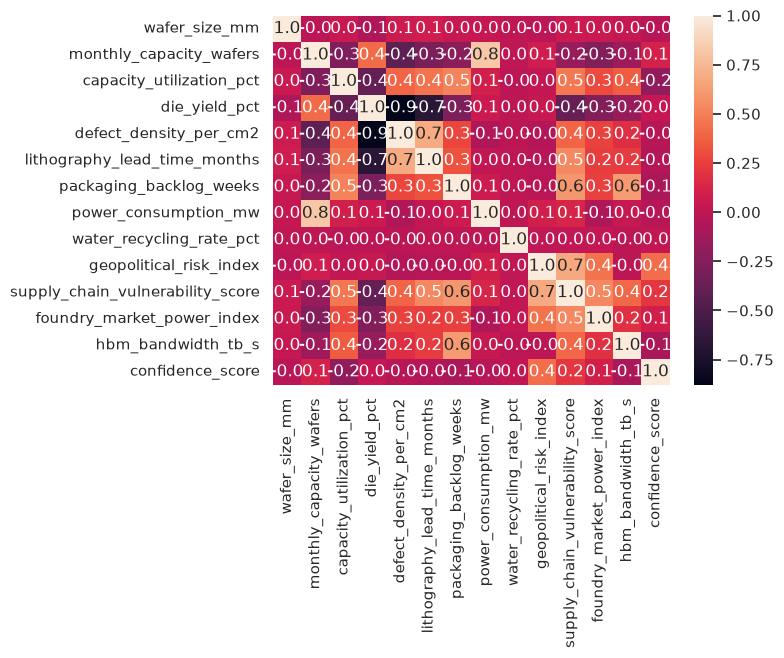

In [8]:
sns.heatmap(corr, fmt='.1f', annot=True)

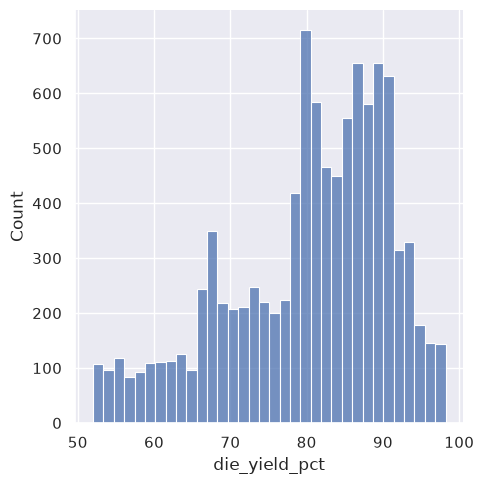

In [9]:
sns.displot(x='die_yield_pct', data=semi)

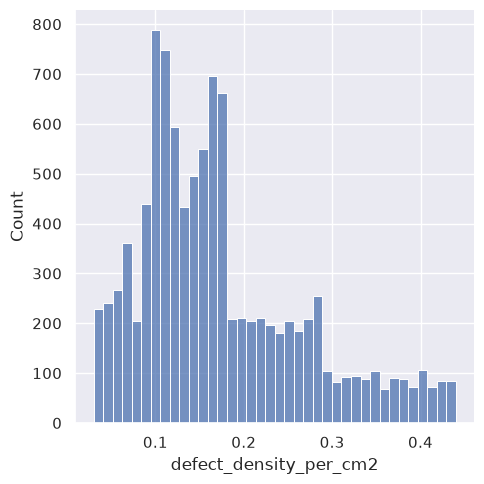

In [10]:
sns.displot(x='defect_density_per_cm2', data=semi)	

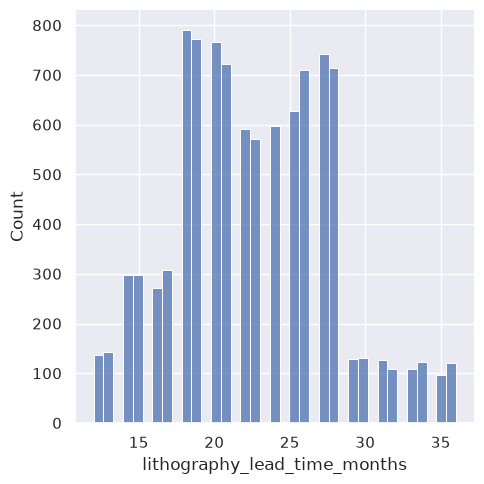

In [11]:
sns.displot(x='lithography_lead_time_months', data=semi)

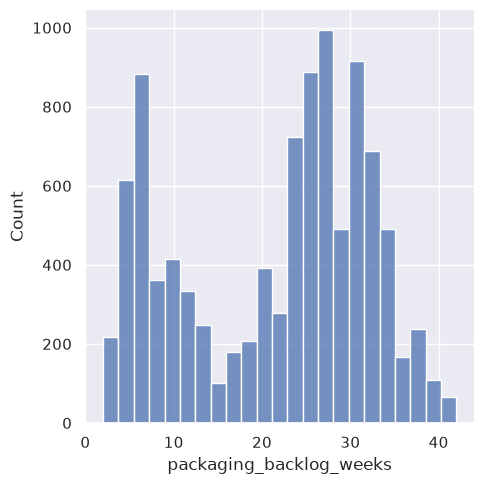

In [12]:
sns.displot(x='packaging_backlog_weeks', data=semi)

Interesting, the packaging backlog seems to be bimodal.

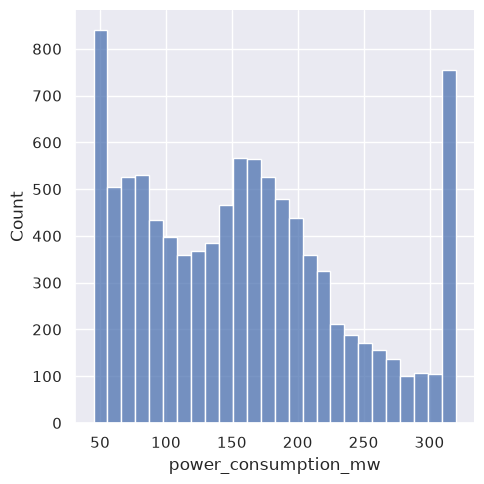

In [13]:
sns.displot(x='power_consumption_mw', data=semi)

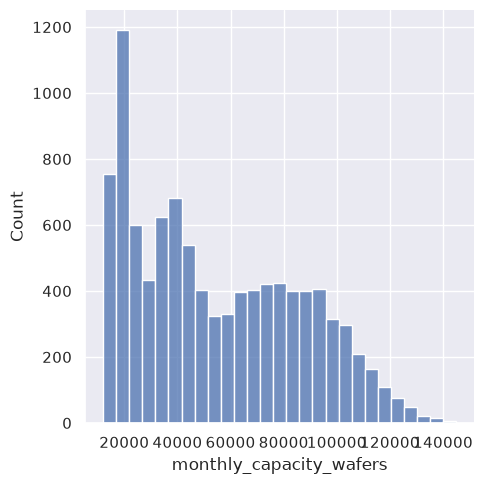

In [14]:
sns.displot(x='monthly_capacity_wafers', data=semi)

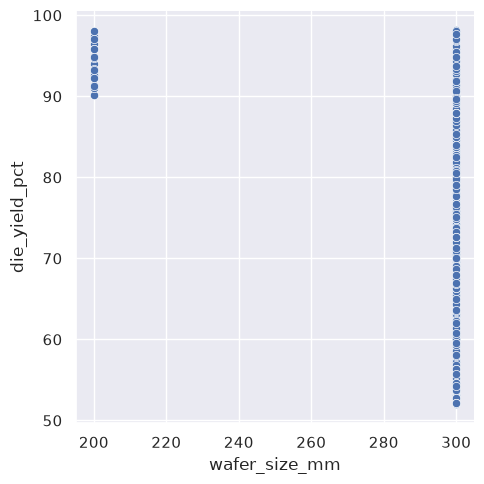

In [15]:
sns.relplot(x='wafer_size_mm', y='die_yield_pct', data=semi)

<Axes: xlabel='wafer_size_mm', ylabel='die_yield_pct'>

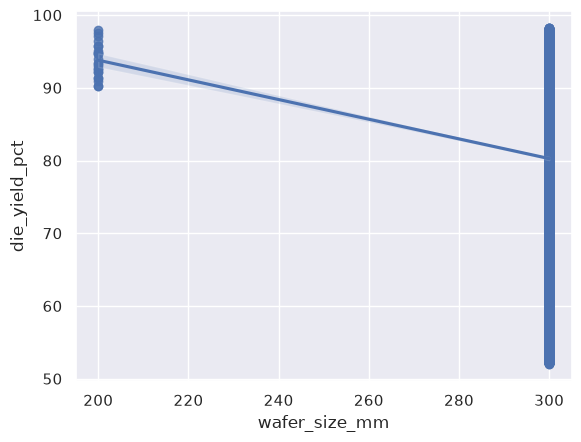

In [16]:
sns.regplot(x='wafer_size_mm', y='die_yield_pct', data=semi)

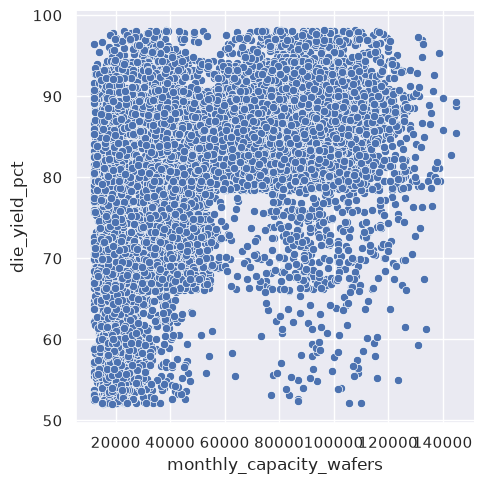

In [17]:
sns.relplot(x='monthly_capacity_wafers', y='die_yield_pct', data=semi)

<Axes: xlabel='monthly_capacity_wafers', ylabel='die_yield_pct'>

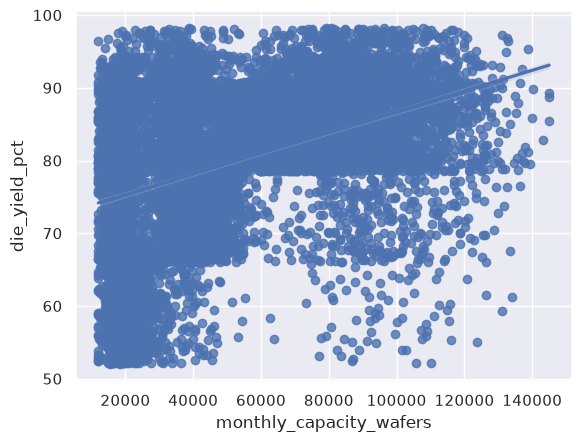

In [18]:
sns.regplot(x='monthly_capacity_wafers', y='die_yield_pct', data=semi)

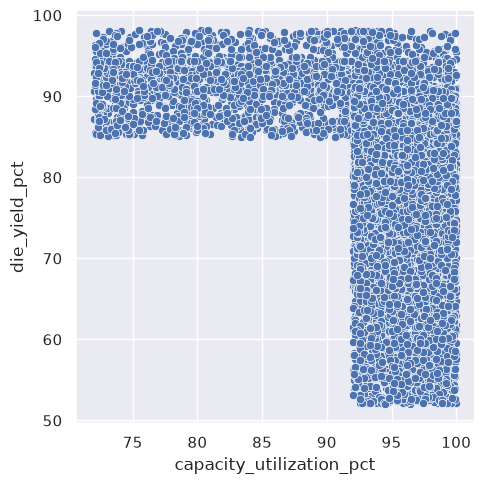

In [19]:
sns.relplot(x='capacity_utilization_pct', y='die_yield_pct', data=semi)

<Axes: xlabel='capacity_utilization_pct', ylabel='die_yield_pct'>

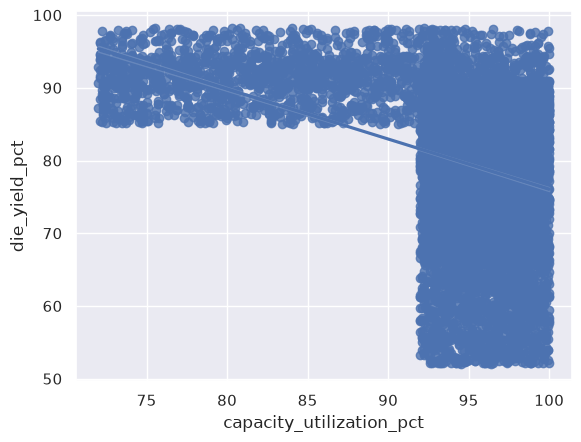

In [20]:
sns.regplot(x='capacity_utilization_pct', y='die_yield_pct', data=semi)

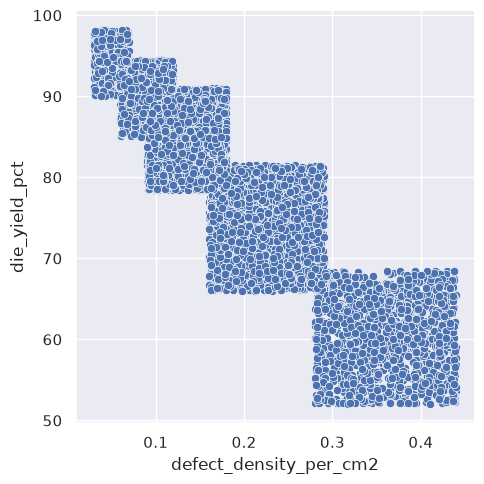

In [21]:
sns.relplot(x='defect_density_per_cm2', y='die_yield_pct', data=semi)

<Axes: xlabel='defect_density_per_cm2', ylabel='die_yield_pct'>

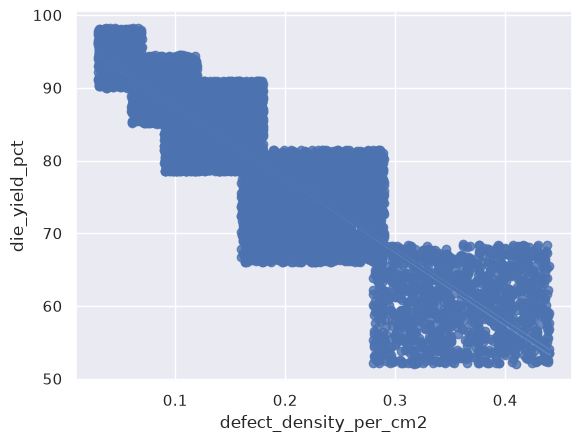

In [22]:
sns.regplot(x='defect_density_per_cm2', y='die_yield_pct', data=semi)

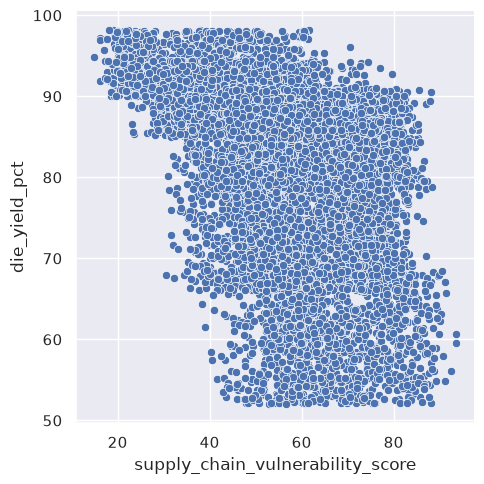

In [23]:
sns.relplot(x='supply_chain_vulnerability_score', y='die_yield_pct', data=semi)

<Axes: xlabel='supply_chain_vulnerability_score', ylabel='die_yield_pct'>

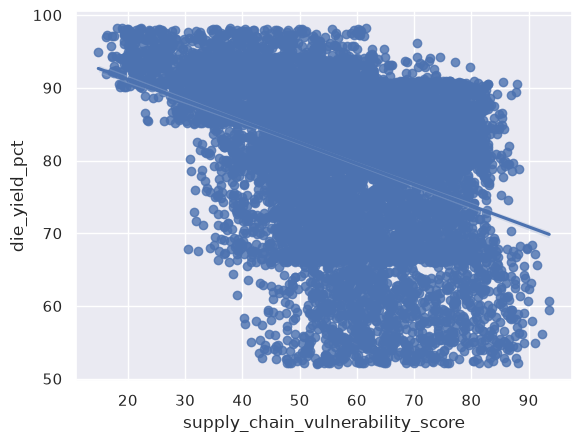

In [24]:
sns.regplot(x='supply_chain_vulnerability_score', y='die_yield_pct', data=semi)

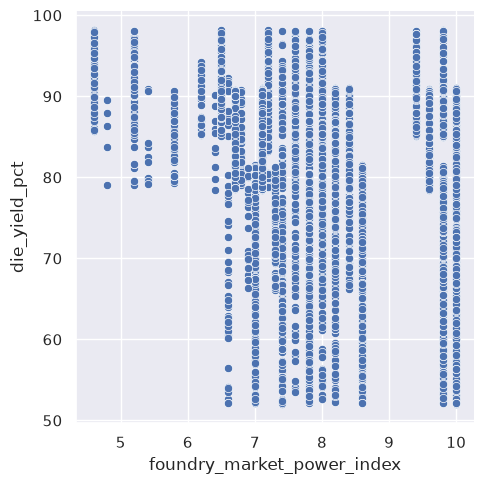

In [25]:
sns.relplot(x='foundry_market_power_index', y='die_yield_pct', data=semi)

<Axes: xlabel='foundry_market_power_index', ylabel='die_yield_pct'>

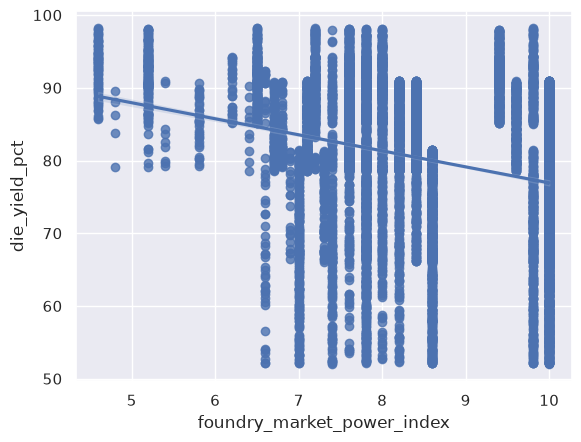

In [26]:
sns.regplot(x='foundry_market_power_index', y='die_yield_pct', data=semi)

### Modeling

In [27]:
results = smf.ols('die_yield_pct ~ 	wafer_size_mm + monthly_capacity_wafers + capacity_utilization_pct + defect_density_per_cm2 + lithography_lead_time_months + packaging_backlog_weeks + power_consumption_mw	+ water_recycling_rate_pct + geopolitical_risk_index + supply_chain_vulnerability_score + foundry_market_power_index + hbm_bandwidth_tb_s + confidence_score', data=semi).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          die_yield_pct   R-squared:                       0.796
Model:                            OLS   Adj. R-squared:                  0.795
Method:                 Least Squares   F-statistic:                     2989.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:18:53   Log-Likelihood:                -29840.
No. Observations:               10000   AIC:                         5.971e+04
Df Residuals:                    9986   BIC:                         5.981e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                          113.9516      3.978     28.643      0.000     106.153     121.750
wafer_size_mm                        0.0033      0.010      0.326      0.744      -0.016       0.023
monthly_capacity_wafers              0.0001   4.38e-06     22.916      0.000    9.17e-05       0.000
capacity_utilization_pct             0.0414      0.011      3.715      0.000       0.020       0.063
defect_density_per_cm2             -79.9085      0.808    -98.935      0.000     -81.492     -78.325
lithography_lead_time_months        -0.1807      0.026     -6.911      0.000      -0.232      -0.129
packaging_backlog_weeks              0.0282      0.015      1.897      0.058      -0.001       0.057
power_consumption_mw                -0.0318      0.002    -20.294      0.000      -0.035      -0.029
water_recycling_rate_pct            -0.0025      0.011     -0.228      0.820      -0.024       0.019
geopolitical_risk_index              0.2581      0.083      3.094      0.002       0.095       0.422
supply_chain_vulnerability_score    -0.0382      0.023     -1.682      0.093      -0.083       0.006
foundry_market_power_index          -0.0686      0.048     -1.427      0.154      -0.163       0.026
hbm_bandwidth_tb_s                   0.2253      0.083      2.730      0.006       0.064       0.387
confidence_score                   -21.5028      2.329     -9.234      0.000     -26.068     -16.938
==============================================================================
Omnibus:                       48.372   Durbin-Watson:                   1.994
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               48.774
Skew:                          -0.166   Prob(JB):                     2.56e-11
Kurtosis:                       2.916   Cond. No.                     5.59e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.59e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

I'll try the significant variables.

In [28]:
results = smf.ols('die_yield_pct ~ monthly_capacity_wafers + capacity_utilization_pct + defect_density_per_cm2 + lithography_lead_time_months + power_consumption_mw + geopolitical_risk_index + hbm_bandwidth_tb_s + confidence_score', data=semi).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          die_yield_pct   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.795
Method:                 Least Squares   F-statistic:                     4855.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:18:53   Log-Likelihood:                -29842.
No. Observations:               10000   AIC:                         5.970e+04
Df Residuals:                    9991   BIC:                         5.977e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                      113.5898      2.390     47.535      0.000     108.906     118.274
monthly_capacity_wafers          0.0001   4.19e-06     24.387      0.000    9.39e-05       0.000
capacity_utilization_pct         0.0406      0.011      3.778      0.000       0.020       0.062
defect_density_per_cm2         -80.0181      0.806    -99.274      0.000     -81.598     -78.438
lithography_lead_time_months    -0.2186      0.013    -16.310      0.000      -0.245      -0.192
power_consumption_mw            -0.0324      0.001    -21.668      0.000      -0.035      -0.029
geopolitical_risk_index          0.1075      0.019      5.531      0.000       0.069       0.146
hbm_bandwidth_tb_s               0.2373      0.070      3.411      0.001       0.101       0.374
confidence_score               -20.8457      2.308     -9.031      0.000     -25.370     -16.321
==============================================================================
Omnibus:                       49.427   Durbin-Watson:                   1.994
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               49.830
Skew:                          -0.167   Prob(JB):                     1.51e-11
Kurtosis:                       2.913   Cond. No.                     4.29e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.29e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Machine learning yield prediction model

With the significant predictors identified, I want to build a predictive regression model.

In [29]:
from sklearn.linear_model import LinearRegression

In [30]:
X = semi[['monthly_capacity_wafers', 'capacity_utilization_pct', 'defect_density_per_cm2', 'lithography_lead_time_months', 'power_consumption_mw', 'geopolitical_risk_index', 'hbm_bandwidth_tb_s', 'confidence_score']] 	

In [31]:
y = semi['die_yield_pct']

In [32]:
model = LinearRegression().fit(X,y)

In [33]:
model.intercept_

np.float64(98.11905868517091)

In [34]:
model.coef_

array([ 9.44363429e-05,  4.67249201e-02, -8.09166511e+01, -2.22732785e-01,
       -2.96603476e-02,  4.35524415e-02,  2.38102117e-01, -4.42881848e+00])

It's identical to the statsmodels version. I want to cross-validate it to see how it would perform on unseen data.

In [35]:
from sklearn.model_selection import cross_val_score

In [36]:
cross_val_score(model,X,y)

array([0.82206323, 0.76993489, 0.78259767, 0.79523517, 0.77570994])

The cross-validation seems consistent.